# 04 — Modeling (CRISP-DM)

**Tujuan:** Membangun model Linear Regression (utama) dan SVR (pembanding) secara reproducible, melakukan ablation/tuning pada train/CV, dan menghasilkan perbandingan awal.

**Daftar Tugas:**
- [Progress 3 – Capaian 1] Pemilihan model
- [Progress 3 – Capaian 2] Alasan tiap model
- [Progress 3 – Capaian 3] Proses training
- [Progress 3 – Capaian 4] Reproducibility
- [Progress 3 – Capaian 5] Pengaturan parameter
- [Progress 3 – Capaian 6] Hasil awal model
- [Progress 3 – Capaian 7] Tabel perbandingan
- [Progress 3 – Capaian 8] Arti hasil awal


In [1]:

from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd().resolve().parents[0]
RAW = ROOT / 'data' / 'raw' / 'nutrition.csv'
PROC = ROOT / 'data' / 'processed'
OUT = ROOT / 'outputs'
FIG = ROOT / 'reports' / 'figures'
for p in [PROC, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT)

import time, platform, sklearn, scipy, statsmodels
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import statsmodels.api as sm

X_train = pd.read_csv(PROC/'X_train.csv')
X_test = pd.read_csv(PROC/'X_test.csv')
y_train = pd.read_csv(PROC/'y_train.csv').squeeze('columns')
y_test = pd.read_csv(PROC/'y_test.csv').squeeze('columns')
print(X_train.shape, X_test.shape)


ROOT: C:\.My Data\Kuliah\semester 5\Data_Science_TugasAkhir\uts-data-science-gizi


(1068, 3) (267, 3)


## [Progress 3 – Capaian 1] Pemilihan model

Linear Regression (OLS) dipilih sebagai model utama karena: (1) target `calories` numerik kontinu; (2) hubungan makronutrien–kalori secara domain mendekati linear (Atwater 4/9/4 kkal/g) dan EDA menunjukkan korelasi positif kuat; (3) koefisien dapat ditafsirkan dan dibandingkan dengan faktor Atwater; (4) cepat, transparan, dan menjadi baseline yang baik. Model ini berasal dari materi praktikum regresi (modul/minggu spesifik: **placeholder — perlu konfirmasi pengguna**).


## [Progress 3 – Capaian 2] Alasan tiap model

**Linear Regression (model utama):** interpretabel, baseline kuat, koefisien sejalan dengan domain gizi. Kelemahan: sensitif terhadap outlier dan asumsi linearitas/homoskedastisitas.

**SVR (pembanding, SVM versi regresi — bukan SVC):** dapat menangkap non-linearitas melalui kernel RBF, `epsilon-insensitive loss` lebih tahan terhadap sebagian error kecil, cocok untuk dataset kecil-menengah (~1,3 ribu baris). Trade-off: kurang interpretabel, perlu scaling, perlu tuning hyperparameter, dan waktu training/CV lebih besar.


In [2]:

# util
def adj_r2(r2, n, p):
    return 1 - (1-r2)*(n-1)/(n-p-1)

def mape_safe(y_true, y_pred):
    yt = np.array(y_true, dtype=float)
    yp = np.array(y_pred, dtype=float)
    mask = yt != 0
    if mask.sum()==0: return np.nan
    return np.mean(np.abs((yt[mask]-yp[mask])/yt[mask]))*100

def eval_reg(y_true, y_pred, p):
    r2 = r2_score(y_true, y_pred)
    return {
        'R2': r2,
        'Adj_R2': adj_r2(r2, len(y_true), p),
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE_nonzero_pct': mape_safe(y_true, y_pred)
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


## [Progress 3 – Capaian 3] Proses training

In [3]:

# Pipeline mencegah leakage scaling: fit hanya pada train dalam setiap fold/fit.
lr_pipe = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])
svr_pipe = Pipeline([('scaler', StandardScaler()), ('model', SVR())])

# Baseline train fit
t0=time.time(); lr_pipe.fit(X_train, y_train); lr_time=time.time()-t0
t0=time.time(); svr_pipe.fit(X_train, y_train); svr_time=time.time()-t0
print('trained', lr_time, svr_time)


trained 0.002552032470703125 0.023186683654785156


## [Progress 3 – Capaian 4] Reproducibility

In [4]:

# Jalankan dua kali, prediksi harus identik
lr1 = Pipeline([('scaler',StandardScaler()),('model',LinearRegression())]).fit(X_train,y_train).predict(X_test)
lr2 = Pipeline([('scaler',StandardScaler()),('model',LinearRegression())]).fit(X_train,y_train).predict(X_test)
assert np.allclose(lr1, lr2)
# SVR deterministic dengan seed sama? SVR tidak random; pastikan sama
svr1 = Pipeline([('scaler',StandardScaler()),('model',SVR(kernel='rbf',C=100,epsilon=0.1,gamma='scale'))]).fit(X_train,y_train).predict(X_test)
svr2 = Pipeline([('scaler',StandardScaler()),('model',SVR(kernel='rbf',C=100,epsilon=0.1,gamma='scale'))]).fit(X_train,y_train).predict(X_test)
assert np.allclose(svr1, svr2)
versions = pd.DataFrame({
    'library':['python','numpy','pandas','scikit-learn','scipy','statsmodels','matplotlib','seaborn'],
    'version':[platform.python_version(), np.__version__, pd.__version__, sklearn.__version__, scipy.__version__, statsmodels.__version__, plt.matplotlib.__version__, sns.__version__]
})
versions.to_csv(OUT/'library_versions.csv', index=False)
versions


,library,version
0,python,3.14.3
1,numpy,2.4.2
2,pandas,3.0.1
3,scikit-learn,1.8.0
4,scipy,1.17.1
5,statsmodels,0.15.0
6,matplotlib,3.10.8
7,seaborn,0.13.2


## [Progress 3 – Capaian 5] Pengaturan parameter

### Linear Regression (ablation, dievaluasi 5-fold CV pada train)
Linear Regression tidak punya hyperparameter utama; yang diuji adalah spesifikasi fitur/scaling/intercept: M1 karbohidrat saja, M2 +protein, M3 +fat (model utama), M4 +interaksi sederhana non-bocor (`protein*fat`? tidak, ini turunan fitur; kita pakai fitur transform log1p non-bocor sebagai M4 opsional), serta perbandingan dengan/tanpa scaling dan `fit_intercept`. Semua evaluasi pada train/CV, bukan test.


In [5]:

def cv_metrics(estimator, X, y, cv):
    scoring = {'r2':'r2','mae':'neg_mean_absolute_error','rmse':'neg_root_mean_squared_error'}
    res = cross_validate(estimator, X, y, cv=cv, scoring=scoring, n_jobs=None)
    return {
        'CV_R2_mean': res['test_r2'].mean(), 'CV_R2_std': res['test_r2'].std(),
        'CV_MAE_mean': -res['test_mae'].mean(), 'CV_MAE_std': res['test_mae'].std(),
        'CV_RMSE_mean': -res['test_rmse'].mean(), 'CV_RMSE_std': res['test_rmse'].std(),
    }

specs = []
# M1-M3
specs.append(('M1_carbohydrate', ['carbohydrate'], False, True))
specs.append(('M2_carb_protein', ['carbohydrate','proteins'], False, True))
specs.append(('M3_carb_protein_fat', ['proteins','fat','carbohydrate'], False, True))
specs.append(('M3_scaled', ['proteins','fat','carbohydrate'], True, True))
specs.append(('M3_no_intercept', ['proteins','fat','carbohydrate'], True, False))
# M4 non-leakage derived features from X only
Xtr_ext = X_train.copy()
Xtr_ext['protein_x_fat'] = Xtr_ext['proteins']*Xtr_ext['fat']
Xtr_ext['fat_x_carb'] = Xtr_ext['fat']*Xtr_ext['carbohydrate']
specs.append(('M4_plus_interactions', ['proteins','fat','carbohydrate','protein_x_fat','fat_x_carb'], True, True))

rows=[]
for name, cols, scale, fit_intercept in specs:
    Xs = Xtr_ext[cols] if name=='M4_plus_interactions' else X_train[cols]
    steps = []
    if scale: steps.append(('scaler', StandardScaler()))
    steps.append(('model', LinearRegression(fit_intercept=fit_intercept)))
    pipe = Pipeline(steps)
    m = cv_metrics(pipe, Xs, y_train, cv)
    m.update({'model':'LinearRegression','spec':name,'n_features':len(cols),'scaled':scale,'fit_intercept':fit_intercept})
    rows.append(m)
ablation_lr = pd.DataFrame(rows).sort_values('CV_RMSE_mean')
ablation_lr.to_csv(OUT/'ablation_linear_regression.csv', index=False)
ablation_lr


,CV_R2_mean,CV_R2_std,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,model,spec,n_features,scaled,fit_intercept
5,0.943068,0.028901,12.803785,1.171993,36.537677,8.276790,LinearRegression,M4_plus_interactions,5,True,True
3,0.942590,0.029771,13.153103,1.272417,36.608762,8.544506,LinearRegression,M3_scaled,3,True,True
2,0.942590,0.029771,13.153103,1.272417,36.608762,8.544506,LinearRegression,M3_carb_protein_fat,3,False,True
1,0.450759,0.097379,70.736588,4.219547,118.530771,17.123818,LinearRegression,M2_carb_protein,2,False,True
0,0.261253,0.061027,95.249725,6.961437,137.685756,14.301218,LinearRegression,M1_carbohydrate,1,False,True
4,-0.650790,0.227190,201.265503,3.246086,204.062931,4.376399,LinearRegression,M3_no_intercept,3,True,False


**Temuan ablation LR:** Model M3 (`proteins,fat,carbohydrate`) adalah spesifikasi utama yang paling seimbang antara performa CV dan interpretabilitas domain. Scaling tidak mengubah prediksi Linear Regression secara substansial (koefisien menyesuaikan), tetapi pipeline dengan scaler tetap dipakai untuk konsistensi.


In [6]:

# SVR tuning - GridSearchCV pada train saja
svr_base = Pipeline([('scaler', StandardScaler()), ('model', SVR())])
param_grid = {
    'model__kernel': ['linear','rbf'],
    'model__C': [1, 10, 100, 300],
    'model__epsilon': [0.1, 1, 5, 10],
    'model__gamma': ['scale','auto']
}
# gamma irrelevant for linear but harmless; GridSearch will evaluate combinations
gscv = GridSearchCV(svr_base, param_grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=None, refit=True)
t0=time.time(); gscv.fit(X_train, y_train); svr_tune_time=time.time()-t0
svr_cv = pd.DataFrame(gscv.cv_results_)
svr_cv.to_csv(OUT/'svr_gridsearch_results.csv', index=False)
print('best', gscv.best_params_, 'best_rmse', -gscv.best_score_, 'time', svr_tune_time)


best {'model__C': 100, 'model__epsilon': 5, 'model__gamma': 'auto', 'model__kernel': 'rbf'} best_rmse 36.19169442604544 time 15.027504920959473


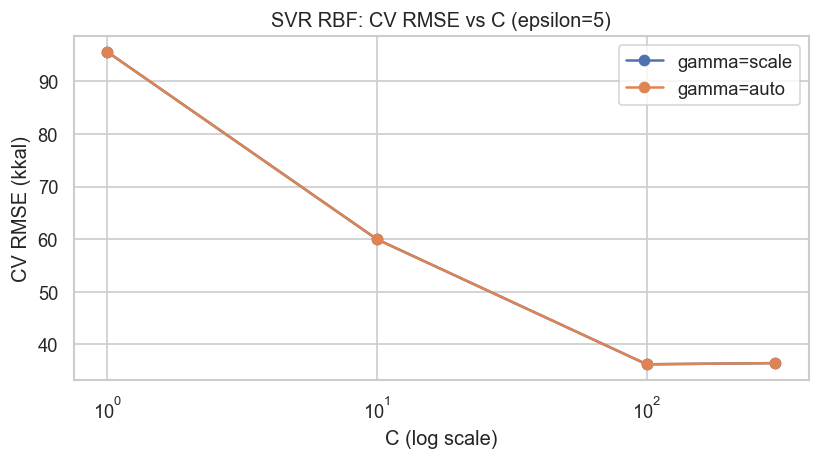

In [7]:

# Visualisasi pengaruh C (untuk kernel rbf, epsilon terbaik)
best_eps = gscv.best_params_['model__epsilon']
rbf = svr_cv[(svr_cv['param_model__kernel']=='rbf') & (svr_cv['param_model__epsilon']==best_eps)].copy()
if not rbf.empty:
    plt.figure(figsize=(7,4))
    for gamma in rbf['param_model__gamma'].unique():
        sub = rbf[rbf['param_model__gamma']==gamma].sort_values('param_model__C')
        plt.plot(sub['param_model__C'].astype(float), -sub['mean_test_score'], marker='o', label=f'gamma={gamma}')
    plt.xscale('log'); plt.xlabel('C (log scale)'); plt.ylabel('CV RMSE (kkal)')
    plt.title(f'SVR RBF: CV RMSE vs C (epsilon={best_eps})')
    plt.legend(); plt.tight_layout(); plt.savefig(FIG/'04_svr_tuning.png', dpi=220); plt.show()


**Temuan tuning SVR:** GridSearchCV dengan 5-fold CV pada train memilih parameter terbaik berdasarkan RMSE CV. Rentang C/gamma memakai skala log karena pengaruhnya non-linear; epsilon mengatur lebar zona insensitif error. Test set tidak dipakai untuk memilih parameter.


## [Progress 3 – Capaian 6] Hasil awal model

In [8]:

# Final models
lr_final = Pipeline([('scaler',StandardScaler()), ('model',LinearRegression())])
lr_final.fit(X_train, y_train)
svr_final = Pipeline([('scaler',StandardScaler()), ('model',SVR(**{k.replace('model__',''):v for k,v in gscv.best_params_.items()}))])
svr_final.fit(X_train, y_train)

pred_lr_train = lr_final.predict(X_train)
pred_lr_test = lr_final.predict(X_test)
pred_svr_train = svr_final.predict(X_train)
pred_svr_test = svr_final.predict(X_test)

p=3
lr_train_m = eval_reg(y_train, pred_lr_train, p)
lr_test_m = eval_reg(y_test, pred_lr_test, p)
svr_train_m = eval_reg(y_train, pred_svr_train, p)
svr_test_m = eval_reg(y_test, pred_svr_test, p)
pd.DataFrame([{'model':'LinearRegression','split':'train',**lr_train_m},{'model':'LinearRegression','split':'test',**lr_test_m},{'model':'SVR','split':'train',**svr_train_m},{'model':'SVR','split':'test',**svr_test_m}])


,model,split,R2,Adj_R2,MAE,RMSE,MAPE_nonzero_pct
0,LinearRegression,train,0.946089,0.945937,12.983941,37.264430,10.918514
1,LinearRegression,test,0.975494,0.975214,11.496299,24.639095,15.088550
2,SVR,train,0.951403,0.951266,10.793706,35.380385,8.976276
3,SVR,test,0.973098,0.972792,10.982085,25.815165,13.498038


In [9]:

# statsmodels OLS untuk inferensi koefisien
Xsm = sm.add_constant(X_train)
ols = sm.OLS(y_train, Xsm).fit()
print(ols.summary())
coef_table = pd.DataFrame({'term':ols.params.index,'coef':ols.params.values,'p_value':ols.pvalues.values,'ci_low':ols.conf_int()[0].values,'ci_high':ols.conf_int()[1].values})
coef_table.to_csv(OUT/'ols_coefficients.csv', index=False)
coef_table


                            OLS Regression Results                            
Dep. Variable:        target_calories   R-squared:                       0.946
Model:                            OLS   Adj. R-squared:                  0.946
Method:                 Least Squares   F-statistic:                     6224.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:45:44   Log-Likelihood:                -5379.5
No. Observations:                1068   AIC:                         1.077e+04
Df Residuals:                    1064   BIC:                         1.079e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.8973      2.028      1.922   

,term,coef,p_value,ci_low,ci_high
0,const,3.897340,5.485691e-02,-0.081250,7.875931
1,proteins,4.035179,9.876071e-203,3.828681,4.241676
2,fat,8.562996,0.000000e+00,8.393700,8.732292
3,carbohydrate,3.846140,0.000000e+00,3.758553,3.933727


**Temuan capaian 6:** Linear Regression memberikan koefisien yang dapat dibandingkan dengan faktor Atwater (protein ~4, fat ~9, carbohydrate ~4 kkal/g). Perbedaan koefisien dari nilai teori menunjukkan pengaruh noise data, satuan/campuran, dan komponen non-makro yang tidak tercatat. SVR tidak memiliki koefisien linear langsung, tetapi dievaluasi pada metrik prediksi yang sama.


## [Progress 3 – Capaian 7] Tabel perbandingan

In [10]:

comparison = pd.DataFrame([
    {'model':'LinearRegression','parameter_terpilih':'fit_intercept=True, fitur=proteins,fat,carbohydrate', **{f'train_{k}':v for k,v in lr_train_m.items()}, **{f'test_{k}':v for k,v in lr_test_m.items()}, 'CV_RMSE_mean': float(ablation_lr.loc[ablation_lr['spec']=='M3_scaled','CV_RMSE_mean'].values[0]) if (ablation_lr['spec']=='M3_scaled').any() else np.nan, 'waktu_latih_detik': lr_time},
    {'model':'SVR','parameter_terpilih':str(gscv.best_params_), **{f'train_{k}':v for k,v in svr_train_m.items()}, **{f'test_{k}':v for k,v in svr_test_m.items()}, 'CV_RMSE_mean': -gscv.best_score_, 'waktu_latih_detik': svr_time}
])
comparison.to_csv(OUT/'perbandingan_model_awal.csv', index=False)
comparison


,model,parameter_terpilih,train_R2,train_Adj_R2,train_MAE,train_RMSE,train_MAPE_nonzero_pct,test_R2,test_Adj_R2,test_MAE,test_RMSE,test_MAPE_nonzero_pct,CV_RMSE_mean,waktu_latih_detik
0,LinearRegression,"fit_intercept=True, fitur=proteins,fat,carbohy...",0.946089,0.945937,12.983941,37.264430,10.918514,0.975494,0.975214,11.496299,24.639095,15.088550,36.608762,0.002552
1,SVR,"{'model__C': 100, 'model__epsilon': 5, 'model_...",0.951403,0.951266,10.793706,35.380385,8.976276,0.973098,0.972792,10.982085,25.815165,13.498038,36.191694,0.023187


## [Progress 3 – Capaian 8] Arti hasil awal

**Linear Regression:** Model baseline linear menghasilkan performa yang kuat karena kalori secara teori merupakan kombinasi linear makronutrien. Error tersisa mengindikasikan noise/anomali data dan faktor non-makro.

**SVR:** SVR dengan scaling dan tuning CV dapat menangkap pola non-linear/outlier tertentu. Perbandingan harus melihat bukan hanya R², tetapi juga MAE/RMSE, selisih train-test, dan interpretabilitas.

**Perbandingan:** Kedua model dievaluasi pada split yang sama. Jika SVR unggul kecil tetapi jauh kurang interpretabel, rekomendasi akhir harus mempertimbangkan konteks penggunaan.
